# Sri Lanka Tourism Sector Analysis: Arrivals & Revenue Trends (2026)
**Author:** Lisaja Sanketh

## Project Overview
This project analyzes the performance of Sri Lanka's tourism industry from January to October 2026. Using official datasets, this analysis explores monthly tourist arrival trends, identifies key source markets, calculates descriptive statistics, and evaluates the correlation between tourist footfall and foreign exchange earnings (USD Millions).

## Data Source
* **Primary Source:** Sri Lanka Tourism Development Authority (SLTDA) & Central Bank of Sri Lanka (CBSL) official monthly statistical reports for 2026.
* **Data Files:** Monthly tourist arrivals by country and tourism earnings datasets in CSV/Excel format.

## Objectives
* Clean and preprocess raw tourism arrival and earnings datasets.
* Visualize monthly arrival fluctuations to identify peak and off-peak seasons.
* Determine the top 10 tourist source countries contributing to Sri Lanka's tourism.
* Analyze the relationship between monthly tourist arrivals and total revenue generated.

## 1. Environment Setup & Library Imports
Importing essential Python libraries for data manipulation (`pandas`, `numpy`) and data visualization (`matplotlib`, `seaborn`).

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Data Ingestion
Loading the raw datasets from Excel files containing monthly tourist arrivals by country and monthly tourism earnings for the year 2026.

In [23]:
arrivals=pd.read_excel("/kaggle/input/datasets/lisajasanketh/tourismdata/AllCountriesJanOct 2026.xlsx",header=2)
earnings=pd.read_excel("/kaggle/input/datasets/lisajasanketh/tourismdata/table2.14.1_20261030_e.xlsx",header=4)


## 3. Data Cleaning & Preprocessing (Arrivals Dataset)
* Removing irrelevant unnamed columns generated during Excel import.
* Standardizing missing values in the `Country` column to represent the 'Total' row.
* Filtering out duplicate header rows and null entries, followed by resetting the DataFrame index for clean downstream analysis.

In [24]:
arrivals = arrivals.drop(columns=['Unnamed: 0', 'Unnamed: 1'])
arrivals.loc[arrivals['Country'].isna(), 'Country'] = 'Total'
arrivals = arrivals[arrivals['Country'] != 'Country']
arrivals = arrivals[arrivals['Country'].notna()]
arrivals = arrivals.reset_index(drop=True)
arrivals.tail()

,Rank,Country,Jan,Feb,March,April,May,June,July,Aug,Sep,Oct,Total
189,190,Vietnam,354,1627,970,661,444,300,443,698,587,476,6560
190,191,Yemen,45,15,10,10,57,23,93,77,48,33,411
191,192,Zambia,6,15,3,4,5,9,6,11,3,5,67
192,193,Zimbabwe,37,57,11,7,13,6,10,16,20,22,199
193,Total,Total,277327,279328,183979,135643,145745,124551,196845,191704,158557,168625,1862304


## 4. Feature Engineering & Data Integration (Earnings Dataset)
Extracting the 2026 monthly tourism earnings (in USD Millions) and appending them as a summary row to the main dataset. Redundant index rows are dropped to maintain data integrity.

In [25]:
earnings.columns = earnings.columns.str.strip()


col_2026 = [c for c in earnings.columns if '2026' in str(c)][0]

year = earnings[col_2026].tolist()
print(year)

earn_dict = {
    'Rank': '',
    'Country': 'Earnings(USD Mn)',
    'Jan': year[0],
    'Feb': year[1],
    'March': year[2],
    'April': year[3],
    'May': year[4],
    'June': year[5],
    'July': year[6],
    'Aug': year[7],
    'Sep': year[8],
    'Oct': year[9],
    'Total':year[12]

}
earn_row_df = pd.DataFrame([earn_dict])
arrivals = pd.concat([arrivals, earn_row_df], ignore_index=True)

[413.78760823000005, 381.43011571899996, 244.825495, 164.26274714, 155.687769, 151.14029, 285.526132, 264.392538, 185.583186, nan, nan, nan, 2246.6358810889997, nan, nan, nan, nan]


In [26]:

arrivals.tail()

,Rank,Country,Jan,Feb,March,April,May,June,July,Aug,Sep,Oct,Total
190,191,Yemen,45,15,10,10,57,23,93,77,48,33,411
191,192,Zambia,6,15,3,4,5,9,6,11,3,5,67
192,193,Zimbabwe,37,57,11,7,13,6,10,16,20,22,199
193,Total,Total,277327,279328,183979,135643,145745,124551,196845,191704,158557,168625,1862304
194,,Earnings(USD Mn),413.787608,381.430116,244.825495,164.262747,155.687769,151.14029,285.526132,264.392538,185.583186,NaN,2246.635881


## 5. Exploratory Data Analysis (EDA)

### 5.1 Monthly Tourist Arrivals Trend (Jan – Oct 2026)
Visualizing the monthly trajectory of international tourist arrivals to observe seasonal patterns, peak months, and mid-year dips.

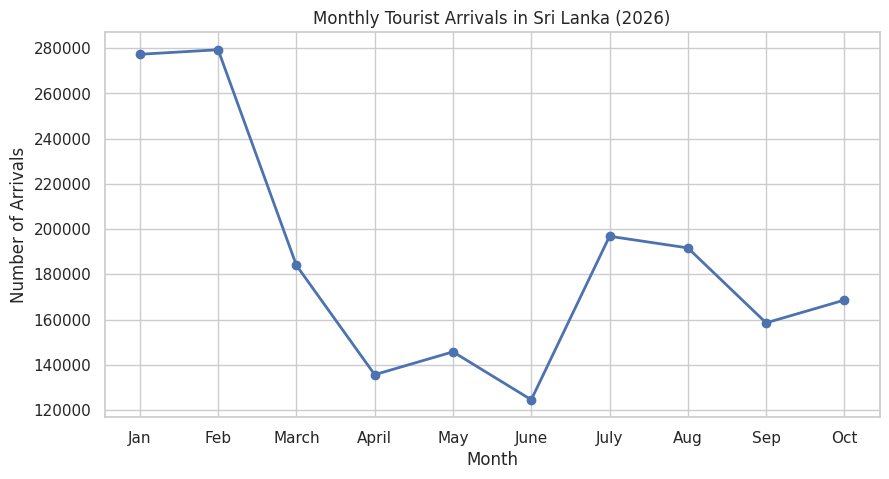

In [27]:
import matplotlib.pyplot as plt


total_row = arrivals[arrivals['Country'] == 'Total'].iloc[0]

months = ['Jan', 'Feb', 'March', 'April', 'May', 'June', 'July', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

arrival_values = [total_row[m] for m in months if m in total_row and pd.notna(total_row[m])]

plt.figure(figsize=(10, 5))
plt.plot(months[:len(arrival_values)], arrival_values, marker='o', color='b', linewidth=2)
plt.title('Monthly Tourist Arrivals in Sri Lanka (2026)')
plt.xlabel('Month')
plt.ylabel('Number of Arrivals')
plt.grid(True)
plt.show()

> **Key Insight:** Tourist arrivals peaked during the winter season in **January (277,327)** and **February (279,328)**, experienced a seasonal decline between April and June, and showed a strong recovery in **July (196,845)** and **August (191,704)**.

### 5.2 Top 10 Tourist Source Markets
Filtering out aggregate rows (`Total`, `Earnings`) and ranking countries based on cumulative arrivals to identify Sri Lanka's primary tourism markets.

/tmp/ipykernel_49/1759817460.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  countries_df['Total'] = pd.to_numeric(countries_df['Total'], errors='coerce')


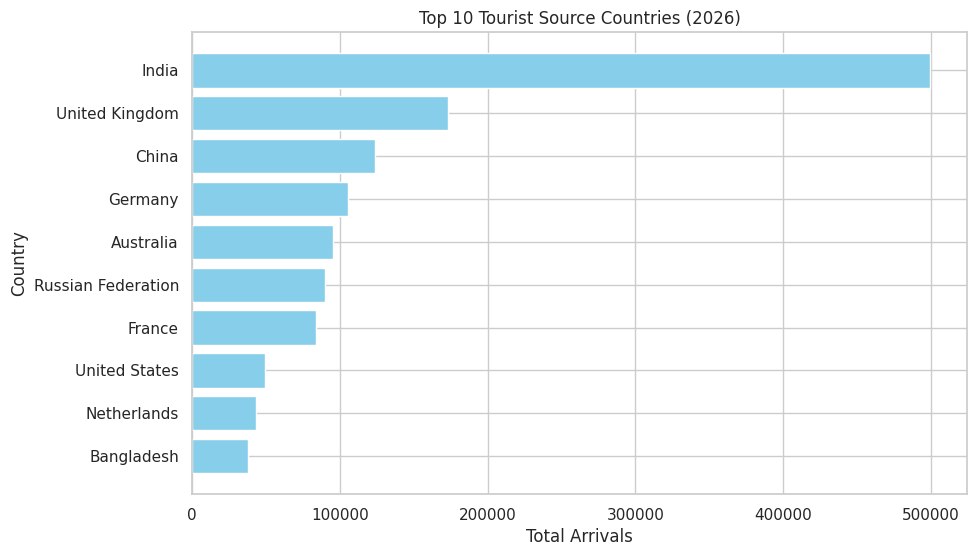

In [28]:
countries_df = arrivals[~arrivals['Country'].isin(['Total', 'Earn'])]


countries_df['Total'] = pd.to_numeric(countries_df['Total'], errors='coerce')
top_10 = countries_df.sort_values(by='Total', ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_10['Country'], top_10['Total'], color='skyblue')
plt.xlabel('Total Arrivals')
plt.ylabel('Country')
plt.title('Top 10 Tourist Source Countries (2026)')
plt.gca().invert_yaxis() 
plt.show()

> **Key Insight:** Identifying the top 10 source countries allows stakeholders and policymakers to tailor targeted marketing campaigns and optimize flight connectivity for high-performing regions.

### 5.3 Descriptive Statistics of Monthly Arrivals
Calculating core statistical metrics—including the monthly mean, peak arrival volume, and lowest monthly footfall—to summarize overall performance across the 10-month period.

In [29]:
import pandas as pd


total_row = arrivals[arrivals['Country'] == 'Total'].iloc[0]


months = ['Jan', 'Feb', 'March', 'April', 'May', 'June', 'July', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']


monthly_arrivals = []
active_months = []

for m in months:
    if m in total_row and pd.notna(total_row[m]):
        try:
            val = float(total_row[m])
            monthly_arrivals.append(val)
            active_months.append(m)
        except ValueError:
            pass


mean_tourists = sum(monthly_arrivals) / len(monthly_arrivals)
max_tourists = max(monthly_arrivals)
min_tourists = min(monthly_arrivals)

print(f"--- Monthly Tourist Statistics (2026) ---")
print(f"Mean (Average) Tourists per Month : {mean_tourists:,.2f}")
print(f"Maximum Arrivals in a Month       : {max_tourists:,.0f}")
print(f"Minimum Arrivals in a Month       : {min_tourists:,.0f}")

--- Monthly Tourist Statistics (2026) ---
Mean (Average) Tourists per Month : 186,230.40
Maximum Arrivals in a Month       : 279,328
Minimum Arrivals in a Month       : 124,551


### 5.4 Correlation Analysis: Tourist Arrivals vs. Tourism Earnings
A dual-axis comparison evaluating whether fluctuations in tourist headcount directly translate to proportional changes in foreign exchange earnings (USD Millions).

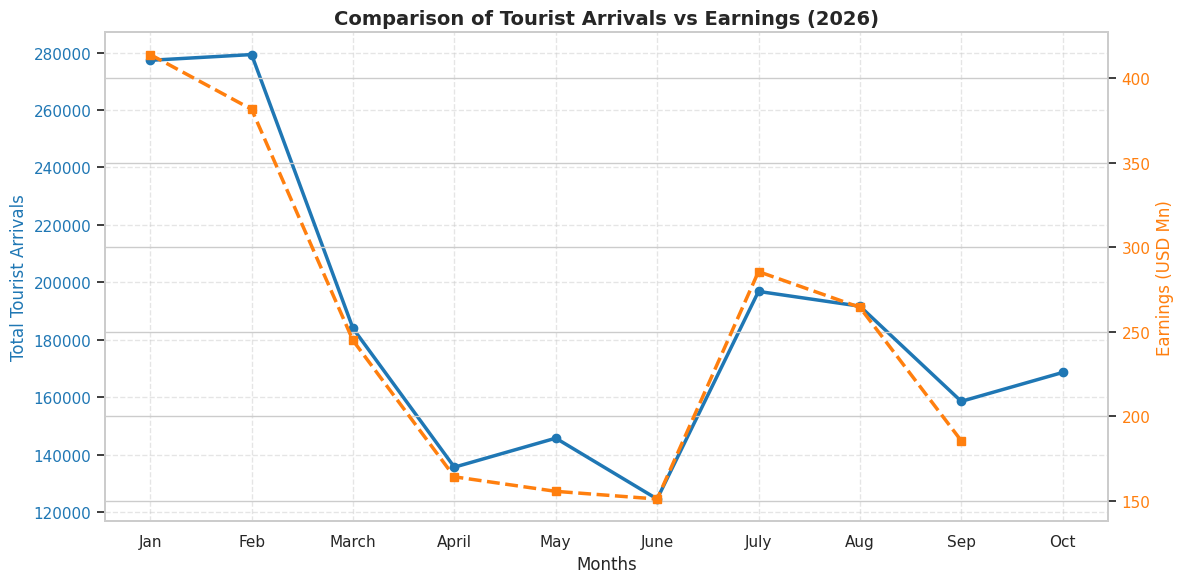

In [30]:
import matplotlib.pyplot as plt


earn_row = arrivals[arrivals['Country'] == 'Earnings(USD Mn)'].iloc[0]
total_row = arrivals[arrivals['Country'] == 'Total'].iloc[0]

arrival_vals = [float(total_row[m]) for m in active_months]
earnings_vals = [float(earn_row[m]) for m in active_months]


fig, ax1 = plt.subplots(figsize=(12, 6))


color = 'tab:blue'
ax1.set_xlabel('Months', fontsize=12)
ax1.set_ylabel('Total Tourist Arrivals', color=color, fontsize=12)
line1 = ax1.plot(active_months, arrival_vals, color=color, marker='o', linewidth=2.5, label='Arrivals')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)


ax2 = ax1.twinx()  
color = 'tab:orange'
ax2.set_ylabel('Earnings (USD Mn)', color=color, fontsize=12)
line2 = ax2.plot(active_months, earnings_vals, color=color, marker='s', linestyle='--', linewidth=2.5, label='Earnings')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Comparison of Tourist Arrivals vs Earnings (2026)', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

> **Key Insight:** There is a strong positive correlation between tourist arrivals and revenue. High-arrival months (January and February) generated over **$380M–$413M** per month, whereas lower footfall in June resulted in the lowest monthly revenue (**$151.14M**). Note that October earnings data is currently pending publication (`NaN`).

---

## 6. Conclusion & Recommendations
* **Seasonality Management:** Introduce promotional campaigns and off-peak travel incentives between April and June to stabilize year-round arrivals.
* **Market Diversification:** While continuing to nurture the top 10 source markets, allocate marketing budgets toward emerging high-spending regions to maximize revenue per tourist.
* **Data Completeness:** Update the model once Q4 (October–December) earnings figures are officially released to complete the annual fiscal assessment.